# SMS Spam Classification Using Multinomial Naive Bayes

## 1. Project Overview

This project develops a machine-learning model to classify SMS messages into two categories: **ham** (legitimate messages) and **spam** (unwanted or potentially fraudulent messages).

The project uses the **Multinomial Naive Bayes** algorithm, a probabilistic classification technique commonly used for text-classification tasks. The model converts messages into word-count features and learns patterns associated with spam and legitimate messages.

## 2. Objectives

- Load and inspect a real-world SMS message dataset.
- Clean the data and examine the distribution of spam and legitimate messages.
- Convert text into numerical features using `CountVectorizer`.
- Train a Multinomial Naive Bayes classifier.
- Evaluate performance using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix.
- Test the trained model on new SMS messages and discuss its limitations.

## 3. Dataset

The dataset contains SMS messages labelled as `ham` or `spam`. It is sourced from the [SMS Spam Collection tutorial dataset](https://github.com/justmarkham/pycon-2016-tutorial).

The notebook checks for missing values, empty messages, duplicate rows, and unexpected labels before training.

## 4. Machine-Learning Approach

- **Learning type:** Supervised learning
- **Task:** Binary text classification
- **Feature extraction:** Bag-of-words using `CountVectorizer`
- **Classification algorithm:** Multinomial Naive Bayes
- **Data split:** 80% training and 20% testing, using stratified sampling
- **Evaluation:** Classification metrics and error analysis

## 5. Workflow

Dataset loading → Data inspection and cleaning → Exploratory analysis → Train/test split → Text vectorization and model training → Evaluation → Example predictions

## 6. Expected Outcome

The goal is to build a reproducible baseline classifier, evaluate how well it distinguishes spam from legitimate messages, and understand the trade-offs between detecting spam and avoiding false alarms.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score
)

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "justmarkham/pycon-2016-tutorial/"
    "master/data/sms.tsv"
)

df = pd.read_csv(
    DATA_URL,
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
print("Column names:", df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique labels:")
print(df["label"].value_counts(dropna=False))

print("\nClass distribution (%):")
print(
    (df["label"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nEmpty messages:", df["message"].str.strip().eq("").sum())

print("\nExample messages:")
display(df.sample(5, random_state=42))

Column names: ['label', 'message']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing values:
label      0
message    0
dtype: int64

Duplicate rows: 403

Unique labels:
label
ham     4825
spam     747
Name: count, dtype: int64

Class distribution (%):
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64

Empty messages: 0

Example messages:


,label,message
3245,ham,Squeeeeeze!! This is christmas hug.. If u lik ...
944,ham,And also I've sorta blown him off a couple tim...
1044,ham,Mmm thats better now i got a roast down me! i...
2484,ham,Mm have some kanji dont eat anything heavy ok
812,ham,So there's a ring that comes with the guys cos...


In [4]:
df = df.dropna(subset=["label", "message"]).copy()

df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()

# Remove empty messages and labels outside the two expected classes.
df = df[
    df["message"].ne("")
    & df["label"].isin(["ham", "spam"])
].copy()

before_deduplication = len(df)

df = df.drop_duplicates(
    subset=["label", "message"]
).reset_index(drop=True)

print("Rows removed as exact duplicates:",
      before_deduplication - len(df))

print("Cleaned dataset shape:", df.shape)
print("\nCleaned class distribution:")
print(df["label"].value_counts())

print("\nRemaining missing values:")
print(df.isna().sum())

Rows removed as exact duplicates: 414
Cleaned dataset shape: (5158, 2)

Cleaned class distribution:
label
ham     4516
spam     642
Name: count, dtype: int64

Remaining missing values:
label      0
message    0
dtype: int64


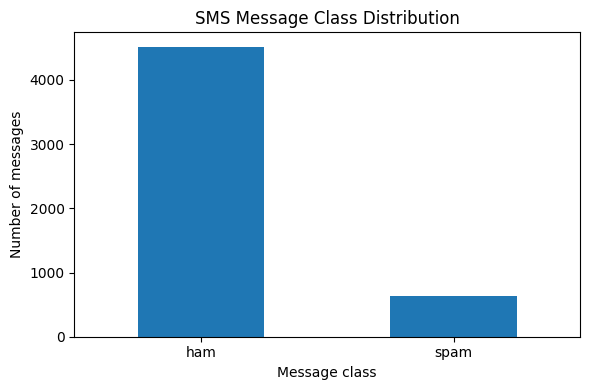

Ham percentage: 87.55
Spam percentage: 12.45


In [5]:
class_counts = df["label"].value_counts().reindex(
    ["ham", "spam"], fill_value=0
)

plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar")
plt.title("SMS Message Class Distribution")
plt.xlabel("Message class")
plt.ylabel("Number of messages")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Ham percentage:",
      round(100 * (df["label"] == "ham").mean(), 2))

print("Spam percentage:",
      round(100 * (df["label"] == "spam").mean(), 2))

## Data Cleaning and Class Distribution

The dataset is inspected for missing values, empty messages, duplicate rows, and class imbalance before model training.

After removing 414 exact duplicate rows, the dataset contains **5,158 messages**: 4,516 ham messages and 642 spam messages. No missing values remain in the cleaned dataset.

Spam messages represent approximately 12.45% of the cleaned data, while ham messages represent 87.55%. This class imbalance makes it important to evaluate precision, recall, and F1-score alongside accuracy.

Stratified train/test splitting helps preserve the original class proportions in both subsets.

In [6]:
X = df["message"]
y = df["label"]

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput example:")
print(X.iloc[0])

print("\nCorresponding target:", y.iloc[0])

Input feature shape: (5158,)
Target shape: (5158,)

Input example:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Corresponding target: ham


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).round(3))

print("\nExact text overlap between train and test:",
      len(set(X_train) & set(X_test)))

Training messages: 4126
Testing messages: 1032

Training class proportions:
label
ham     0.875
spam    0.125
Name: proportion, dtype: float64

Testing class proportions:
label
ham     0.876
spam    0.124
Name: proportion, dtype: float64

Exact text overlap between train and test: 0


## Feature Extraction and Model Training

### CountVectorizer

Machine-learning algorithms require numerical input rather than raw text. `CountVectorizer` converts each SMS message into a vector of word counts using a bag-of-words representation.

For example, the message "win a free prize" is represented using counts for vocabulary terms such as `win`, `free`, and `prize`. Word order and deeper context are not directly represented.

### Multinomial Naive Bayes

Multinomial Naive Bayes is a supervised probabilistic classifier that estimates the likelihood of a message belonging to each class based on its word counts.

Bayes' theorem is:

\[
P(C\mid X)=\frac{P(X\mid C)P(C)}{P(X)}
\]

Here, \(C\) is the class (ham or spam), and \(X\) represents the message's word features.

The algorithm assumes conditional independence between features given the class. Although this assumption is simplified for natural language, the method can perform well for text classification.

The parameter `alpha=1.0` applies Laplace smoothing, preventing unseen words from receiving zero probability under a class.

The vectorizer and classifier are combined in a scikit-learn `Pipeline`, ensuring that vocabulary learning occurs during model fitting on the training data.

In [8]:
model = Pipeline([
    (
        "vectorizer",
        CountVectorizer(
            lowercase=True,
            ngram_range=(1, 1),
            min_df=1
        )
    ),
    (
        "classifier",
        MultinomialNB(alpha=1.0)
    )
])

# Fit both the text vectorizer and classifier using training data only.
model.fit(X_train, y_train)

print("Model training completed successfully.")

vectorizer = model.named_steps["vectorizer"]
classifier = model.named_steps["classifier"]

print("Vocabulary size:", len(vectorizer.vocabulary_))
print("Learned classes:", classifier.classes_)
print("Smoothing parameter alpha:", classifier.alpha)

Model training completed successfully.
Vocabulary size: 7681
Learned classes: ['ham' 'spam']
Smoothing parameter alpha: 1.0


TEST SET EVALUATION
----------------------------------------
Accuracy:  0.9835 (98.35%)
Precision: 0.9587
Recall:    0.9062
F1-score:  0.9317
ROC-AUC:   0.9795

Classification report:
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       904
        spam       0.96      0.91      0.93       128

    accuracy                           0.98      1032
   macro avg       0.97      0.95      0.96      1032
weighted avg       0.98      0.98      0.98      1032


Confusion matrix:
[[899   5]
 [ 12 116]]


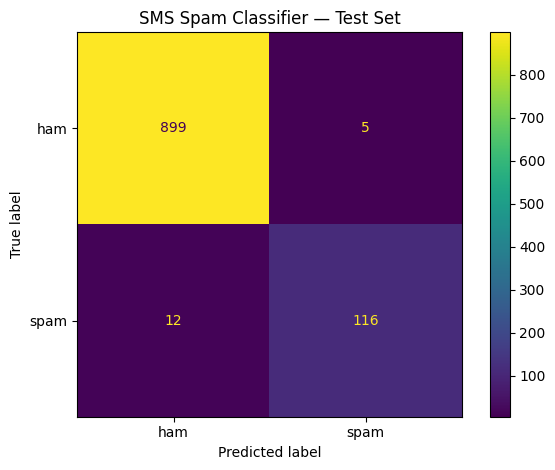

In [9]:
# Generate predictions on the held-out test data.
y_pred = model.predict(X_test)

# Predictive probabilities are available for ROC-AUC.
spam_index = list(model.classes_).index("spam")
y_score = model.predict_proba(X_test)[:, spam_index]

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label="spam", zero_division=0
)

recall = recall_score(
    y_test, y_pred, pos_label="spam", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, pos_label="spam", zero_division=0
)

roc_auc = roc_auc_score(
    (y_test == "spam").astype(int),
    y_score
)

print("TEST SET EVALUATION")
print("-" * 40)
print(f"Accuracy:  {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=["ham", "spam"],
        zero_division=0
    )
)

print("\nConfusion matrix:")
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["ham", "spam"]
)
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["ham", "spam"]
)
disp.plot(values_format="d")
plt.title("SMS Spam Classifier — Test Set")
plt.tight_layout()
plt.show()

## Model Evaluation and Key Findings

The Multinomial Naive Bayes classifier achieved **98.35% test accuracy**, with a spam precision of **95.87%**, recall of **90.62%**, F1-score of **93.17%**, and ROC-AUC of **97.95%**.

Precision indicates how reliably the model identifies messages as spam, while recall measures how much of the actual spam it detects. The results suggest strong classification performance on the held-out test set. However, the model missed some spam messages, so accuracy alone is not sufficient to assess its effectiveness.

The dataset contains more legitimate messages than spam messages. Therefore, precision, recall, F1-score, and the confusion matrix are important complementary evaluation measures.

**Limitations:** Multinomial Naive Bayes uses a conditional-independence assumption for features. The model uses word counts and may struggle with unfamiliar vocabulary, evolving spam tactics, or messages whose meaning depends heavily on context. Test-set performance does not guarantee the same performance on new real-world messages.

In [10]:
# Compare training and test performance.
train_pred = model.predict(X_train)

train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, y_pred)

accuracy_gap = train_accuracy - test_accuracy

print("=" * 52)
print("FINAL MODEL SUMMARY")
print("=" * 52)

print(f"Cleaned dataset size: {len(df)}")
print(f"Training examples:    {len(X_train)}")
print(f"Testing examples:     {len(X_test)}")
print(f"Training accuracy:    {train_accuracy:.4f}")
print(f"Test accuracy:        {test_accuracy:.4f}")
print(f"Accuracy gap:         {accuracy_gap:.4f}")
print(f"Spam precision:       {precision:.4f}")
print(f"Spam recall:          {recall:.4f}")
print(f"Spam F1-score:        {f1:.4f}")
print(f"ROC-AUC:              {roc_auc:.4f}")

print("\nConfusion matrix (rows=actual, columns=predicted):")
print(cm)

print("\nSpam detection errors:")
print(f"False positives (ham flagged as spam): {cm[0, 1]}")
print(f"False negatives (spam missed):          {cm[1, 0]}")

print("\nExample predictions on new messages:")

new_messages = [
    "Hey, are we meeting at the library after class?",
    "Congratulations! You have won a free prize. Claim now!"
]

new_predictions = model.predict(new_messages)
new_probabilities = model.predict_proba(new_messages)

for message, prediction, probabilities in zip(
    new_messages, new_predictions, new_probabilities
):
    spam_probability = probabilities[spam_index]

    print("\nMessage:", message)
    print("Predicted class:", prediction)
    print(f"Estimated spam probability: {spam_probability:.2%}")

print("\nInterpretation:")
if accuracy_gap > 0.05:
    print(
        "Training accuracy is noticeably higher than test accuracy. "
        "Investigate possible overfitting."
    )
elif accuracy_gap < -0.02:
    print(
        "Test accuracy exceeds training accuracy. "
        "This can happen because of sampling variation; investigate if unexpected."
    )
else:
    print(
        "The training-test accuracy gap is relatively small. "
        "This alone does not prove that the model generalizes perfectly."
    )

print(
    "\nThis model is a demonstration baseline, not a guarantee "
    "of reliable real-world spam detection."
)

FINAL MODEL SUMMARY
Cleaned dataset size: 5158
Training examples:    4126
Testing examples:     1032
Training accuracy:    0.9927
Test accuracy:        0.9835
Accuracy gap:         0.0092
Spam precision:       0.9587
Spam recall:          0.9062
Spam F1-score:        0.9317
ROC-AUC:              0.9795

Confusion matrix (rows=actual, columns=predicted):
[[899   5]
 [ 12 116]]

Spam detection errors:
False positives (ham flagged as spam): 5
False negatives (spam missed):          12

Example predictions on new messages:

Message: Hey, are we meeting at the library after class?
Predicted class: ham
Estimated spam probability: 0.00%

Message: Congratulations! You have won a free prize. Claim now!
Predicted class: spam
Estimated spam probability: 100.00%

Interpretation:
The training-test accuracy gap is relatively small. This alone does not prove that the model generalizes perfectly.

This model is a demonstration baseline, not a guarantee of reliable real-world spam detection.


## Conclusion

This project implemented an SMS spam classifier using text vectorization and the Multinomial Naive Bayes algorithm. After cleaning the dataset, the model was trained and evaluated on a stratified 80/20 train/test split.

The classifier achieved **98.35% test accuracy**, **95.87% spam precision**, **90.62% spam recall**, **93.17% spam F1-score**, and **97.95% ROC-AUC**.

The results demonstrate that a lightweight probabilistic model can perform well on this SMS dataset. Precision and recall reveal different aspects of performance: the model makes relatively few false spam alerts but still misses some spam messages.

### Limitations

- The dataset has more legitimate messages than spam messages.
- Bag-of-words features do not capture word order or contextual meaning.
- Spam vocabulary and tactics can change over time.
- Performance on this test set does not guarantee performance on unseen real-world messages.
- Predicted probabilities should not be interpreted as perfectly calibrated confidence estimates.

### Future Improvements

- Compare unigram features with unigram and bigram features.
- Evaluate alternative classifiers using the same train/test split.
- Inspect misclassified messages to understand model weaknesses.
- Evaluate the final model on a separate, newer dataset before real-world use.